# Mouse fib/dec pseudotime — start to finish

**Input:** `data/deliverables/2026_09_02_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad` (the newest mouse fib/dec object;
carries the settled spatial QC — 5 plain MADs + 10 boxes — and `tissue_section`, synced 2026-09-02).

**Steps:** drop `decidual_apoptotic` only (uninduced and `efib_outer` are **kept**) → scVI → neighbours / UMAP /
diffmap → **you choose the root** (§5) → DPT + Palantir → quantile normalisation → violins → spatial plots.

**Run on a GPU node** (`--gres=gpu:1 --mem 200G --cpus-per-task 8`, env `rsc_uv`). §3 is scVI on ~42k cells,
200 epochs. Cells after §3 are CPU-only; if you re-open the notebook later, §3 reloads the saved embedding
instead of retraining.

Conventions carried from the earlier variant work:
- **Palantir must be called with `use_early_cell_as_start=True`** — palantir 1.4.5 ignores `early_cell` by
  default and re-picks its own start (measured 2026-09-02). §6 asserts pseudotime is exactly 0 at your root.
- **DC signs are arbitrary.** §4 measures which end of each component is the early end instead of assuming.
- **Wrong orientation is REFUSED, never flipped.** Pick a different root instead.
- Rooting pins the root's own subtype to 0, so a root drawn from a *late* fibroblast subtype drags every earlier
  subtype behind it (rooting at `efib_subluminal` gave ρ = −0.52 within uninduced last time). §8 checks for this.

Nothing here modifies the deliverable. Outputs go to `results/pseudotime_mouse_final/`.

In [1]:
import pathlib, json, h5py, warnings, os
import numpy as np, pandas as pd, scanpy as sc, anndata as ad
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import spearmanr
warnings.filterwarnings("ignore"); sc.settings.verbosity = 1
try:    from anndata.io import read_elem
except ImportError: from anndata.experimental import read_elem

X   = pathlib.Path("/n/lab_storage/eddy_lab/users/nhilgert/xmens_final")
SRC = X/"data/deliverables/2026_09_02_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad"
ISO = X/"results/isodepth/mouse_fibdec_isodepth_2026_09_02.h5ad"
VARIANT = "with_uninduced"   # each variant owns its output dir so embedding.h5ad caches never collide across notebooks
OUT = X/"results/pseudotime_mouse_final"/VARIANT; OUT.mkdir(parents=True, exist_ok=True)
SEED = 0

# trajectory order (user, 2026-09-02): outer -> middle -> middle_induced -> subluminal -> proliferative -> decidual
SUBORDER = ["efib_outer","efib_middle","efib_middle_induced","efib_subluminal","efib_proliferative",
            "decidual_boundary","decidual_proliferative","decidual_mature"]
TPORDER  = ["uninduced","1_dpi_early","1_dpi_late","2_dpi","3_dpi","4_dpi_bleeding"]
RANK, TPRANK = {s:i for i,s in enumerate(SUBORDER)}, {t:i for i,t in enumerate(TPORDER)}
PAL  = dict(zip(SUBORDER, sns.color_palette("viridis", len(SUBORDER))))
TPAL = dict(zip(TPORDER,  sns.color_palette("rocket_r", len(TPORDER))))

CHECKS = []
def verify(label, got, want=True, note=""):
    ok = bool(got) if isinstance(want, bool) else (got == want)
    CHECKS.append((label, ok, str(got), note))
    print(("PASS  " if ok else "FAIL  ") + label + f"   [{got}]" + (f"  {note}" if note else "")); return ok
print("source:", SRC.name, "| exists:", SRC.exists())

source: 2026_09_02_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad | exists: True


## 1 — load and drop `decidual_apoptotic`

Everything else stays: all six timepoints (uninduced included) and all fibroblast subtypes including `efib_outer`.

In [2]:
a = sc.read_h5ad(SRC)
for c in ("cell_subtype","timepoint","sample"): a.obs[c] = a.obs[c].astype(str)
print("loaded", a.shape, "| layers:", list(a.layers), "| obsm:", list(a.obsm))
verify("counts layer present (scVI input)", "counts" in a.layers)
verify("QC'd coordinates + tissue_section present", {"x_um_qc","y_um_qc","tissue_section"} <= set(a.obs.columns))
print("\nsubtype counts before drop:"); print(a.obs.cell_subtype.value_counts().to_string())

n0 = a.n_obs
keep = (a.obs.cell_subtype != "decidual_apoptotic").to_numpy()
a = a[keep].copy()
print(f"\ndropped decidual_apoptotic: {n0 - a.n_obs:,} cells -> {a.n_obs:,} remain")
verify("decidual_apoptotic gone", "decidual_apoptotic" not in set(a.obs.cell_subtype))
verify("efib_outer kept", "efib_outer" in set(a.obs.cell_subtype))
verify("uninduced kept", "uninduced" in set(a.obs.timepoint))
verify("every remaining subtype is in SUBORDER", set(a.obs.cell_subtype) <= set(SUBORDER),
       note=str(set(a.obs.cell_subtype) - set(SUBORDER)))
print("\nper timepoint:", a.obs.timepoint.value_counts().reindex(TPORDER).to_dict())

loaded (43197, 33698) | layers: ['counts'] | obsm: ['X_scVI', 'X_spatial', 'X_umap', 'X_umap_scVI']
PASS  counts layer present (scVI input)   [True]
PASS  QC'd coordinates + tissue_section present   [True]

subtype counts before drop:
cell_subtype
decidual_proliferative    14434
efib_middle_induced        8775
efib_middle                4764
efib_subluminal            3886
decidual_mature            3856
decidual_boundary          3722
efib_outer                 2073
decidual_apoptotic          907
efib_proliferative          780

dropped decidual_apoptotic: 907 cells -> 42,290 remain
PASS  decidual_apoptotic gone   [True]
PASS  efib_outer kept   [True]
PASS  uninduced kept   [True]
PASS  every remaining subtype is in SUBORDER   [True]  set()

per timepoint: {'uninduced': 9333, '1_dpi_early': 2686, '1_dpi_late': 10656, '2_dpi': 3524, '3_dpi': 10649, '4_dpi_bleeding': 5442}


## 2 — HVGs on counts

Same recipe as the variant grid: 2,000 `seurat_v3` HVGs from the counts layer, batch = `sample`, 30 latent dims, 200 epochs.

In [10]:
HVG = 3000
N_LATENT = 30
EPOCHS = 200
# house standard (2026-09-10): mito/ribo genes are excluded from the HVG candidate pool,
# matching pipeline stages 02_integrate / 04b_reintegrate (same prefix lists). scVI itself
# remains batch-aware. NOTE: the cached embedding.h5ad is reloaded if present -- this patch
# changes nothing until that cache is renamed/removed and the notebook re-run.
a.var["mito"] = a.var_names.str.startswith(("mt-", "Mt-", "MT-"))
a.var["ribo"] = a.var_names.str.startswith(("Rps", "Rpl", "Mrps", "Mrpl", "RPS", "RPL", "MRPS", "MRPL"))
print(f"HVG candidate pool: excluding {int(a.var.mito.sum())} mito + {int(a.var.ribo.sum())} ribo genes")
a_hvg = a[:, (~a.var["mito"]) & (~a.var["ribo"])].copy()
sc.pp.highly_variable_genes(a_hvg, n_top_genes=HVG, flavor="seurat_v3", layer="counts", batch_key="sample")
a.var["highly_variable"] = a.var_names.isin(a_hvg.var_names[a_hvg.var["highly_variable"]])
del a_hvg
av = a[:, a.var["highly_variable"]].copy()
print("HVG matrix:", av.shape)

HVG matrix: (42290, 3000)


## 3 — scVI (GPU) → neighbours → UMAP → diffmap

Reloads `X_scVI` from disk if this notebook has been run before, so the embedding is fixed across re-runs and root choices are comparable.

Seed set to 0


PASS  GPU visible to torch   [True]  scVI on CPU for 42k cells x 200 epochs is hours


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
You are using a CUDA device ('NVIDIA A100-SXM4-80GB') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Training:   0%|          | 0/200 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=200` reached.


embedding saved to /n/lab_storage/eddy_lab/users/nhilgert/xmens_final/results/pseudotime_mouse_final/embedding.h5ad
X_scVI (42290, 10) | X_diffmap (42290, 15) -> DC1..DC14 = columns 1..14


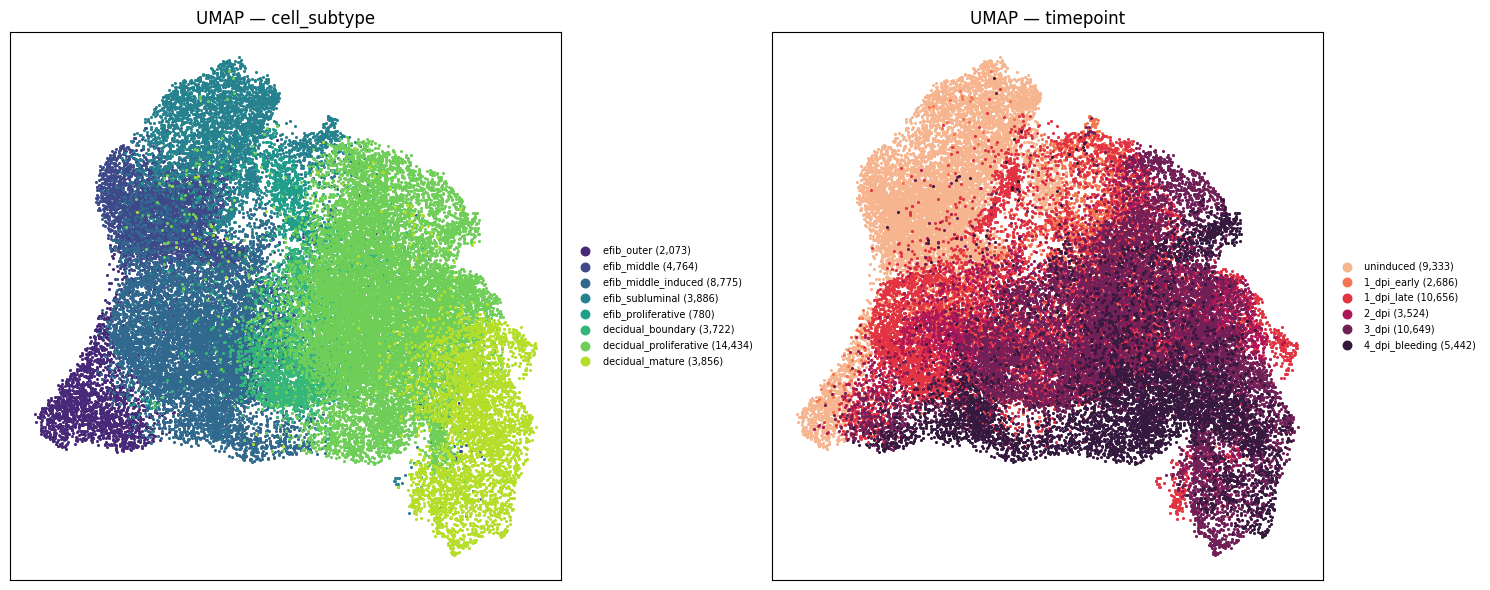

In [11]:
EMB = OUT/"embedding.h5ad"
if EMB.exists():
    e = sc.read_h5ad(EMB)
    same = (len(e.obs_names) == len(a.obs_names)) and (e.obs_names == a.obs_names).all()
    if not same:
        only_saved, only_now = set(e.obs_names) - set(a.obs_names), set(a.obs_names) - set(e.obs_names)
        raise RuntimeError(
            f"saved embedding ({EMB}) was built on a DIFFERENT cell set: saved n={len(e.obs_names):,}, current n={len(a.obs_names):,}; "
            f"{len(only_saved):,} only in saved, {len(only_now):,} only in current. "
            f"Saved trained {e.uns.get('scvi',{}).get('trained_at','?')} with drops={e.uns.get('scvi',{}).get('dropped','?')}. "
            "Rename/delete it to retrain on the current cells (a few GPU minutes).")
    for k in ("X_scVI","X_umap","X_diffmap"): a.obsm[k] = e.obsm[k]
    for k in ("connectivities","distances"): a.obsp[k] = e.obsp[k]
    for k in ("neighbors","diffmap_evals","scvi"): a.uns[k] = e.uns[k]
    print("reloaded embedding from", EMB.name, "| trained:", a.uns["scvi"].get("trained_at"))
else:
    import scvi, torch, datetime
    verify("GPU visible to torch", torch.cuda.is_available(), note="scVI on CPU for 42k cells x 200 epochs is hours")
    scvi.settings.seed = SEED
    scvi.model.SCVI.setup_anndata(av, layer="counts", batch_key="sample")
    model = scvi.model.SCVI(av)
    model.train(max_epochs=EPOCHS, early_stopping = True)
    a.obsm["X_scVI"] = model.get_latent_representation(av)
    a.uns["scvi"] = dict(n_latent=N_LATENT, epochs=EPOCHS, hvg=HVG, batch_key="sample", seed=SEED,
                     exclude_mito_ribo=True,
                         source=str(SRC), dropped=("decidual_apoptotic" if "uninduced" in set(a.obs.timepoint) else "decidual_apoptotic + uninduced"), variant=VARIANT, trained_at=datetime.datetime.now().isoformat())
    sc.pp.neighbors(a, use_rep="X_scVI", n_neighbors=15, random_state=SEED)
    sc.tl.umap(a, random_state=SEED)
    sc.tl.diffmap(a, n_comps=15)
    e = ad.AnnData(obs=a.obs[["cell_subtype","timepoint","sample"]].copy())
    for k in ("X_scVI","X_umap","X_diffmap"): e.obsm[k] = a.obsm[k]
    for k in ("connectivities","distances"): e.obsp[k] = a.obsp[k]
    for k in ("neighbors","diffmap_evals","scvi"): e.uns[k] = a.uns[k]
    e.write_h5ad(EMB); print("embedding saved to", EMB)
O, DM = a.obs, a.obsm["X_diffmap"]; NDC = DM.shape[1] - 1
print("X_scVI", a.obsm["X_scVI"].shape, "| X_diffmap", DM.shape, "-> DC1..DC%d = columns 1..%d" % (NDC, NDC))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (cmap_, col) in zip(axes, ((PAL,"cell_subtype"), (TPAL,"timepoint"))):
    for cat in [s for s in (SUBORDER if col=="cell_subtype" else TPORDER) if s in set(O[col])]:
        m = (O[col]==cat).to_numpy(); ax.scatter(a.obsm["X_umap"][m,0], a.obsm["X_umap"][m,1], s=1.5, c=[cmap_[cat]], label=f"{cat} ({m.sum():,})", rasterized=True)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"UMAP — {col}"); ax.legend(fontsize=7, markerscale=5, loc="center left", bbox_to_anchor=(1.01,.5), frameon=False)
fig.tight_layout()

## 4 — which DC, and which end, is the early end?

`spearman(DC_k, subtype rank)` < 0 means that component runs **backwards** relative to `SUBORDER`, i.e. its *maximum* is the fibroblast (early) pole. Never assume the sign — it flips between embeddings.

,rho_subtype_rank,early_end,low_tail,high_tail
DC,,,,
DC1,-0.889,max,"decidual_mature 100%, decidual_proliferative 0...","efib_outer 100% | uninduced 72%, 1_dpi_late 13%"
DC2,0.527,min,"efib_subluminal 100%, efib_proliferative 0% |...","efib_outer 100% | uninduced 73%, 1_dpi_late 12%"
DC3,0.296,min,"decidual_mature 99%, efib_middle 0% | 3_dpi ...","decidual_proliferative 66%, decidual_boundary ..."
DC4,0.284,min,"efib_middle_induced 64%, decidual_mature 35% ...","efib_subluminal 89%, efib_outer 11% | unindu..."
DC5,0.062,min,"decidual_proliferative 74%, decidual_mature 26...","decidual_mature 94%, decidual_proliferative 6%..."
DC6,0.032,min,"decidual_proliferative 67%, efib_middle 31% |...","efib_subluminal 49%, decidual_mature 39% | u..."
DC7,0.072,min,"efib_middle 37%, decidual_mature 34% | unind...","efib_middle_induced 72%, decidual_mature 26% ..."
DC8,-0.100,max,"decidual_proliferative 50%, decidual_mature 49...","decidual_mature 74%, efib_subluminal 15% | 1..."
DC9,-0.019,max,"decidual_proliferative 47%, efib_proliferative...","decidual_proliferative 75%, decidual_mature 16..."



strongest differentiation axis: DC1 (rho -0.889) -> early end is its MAX


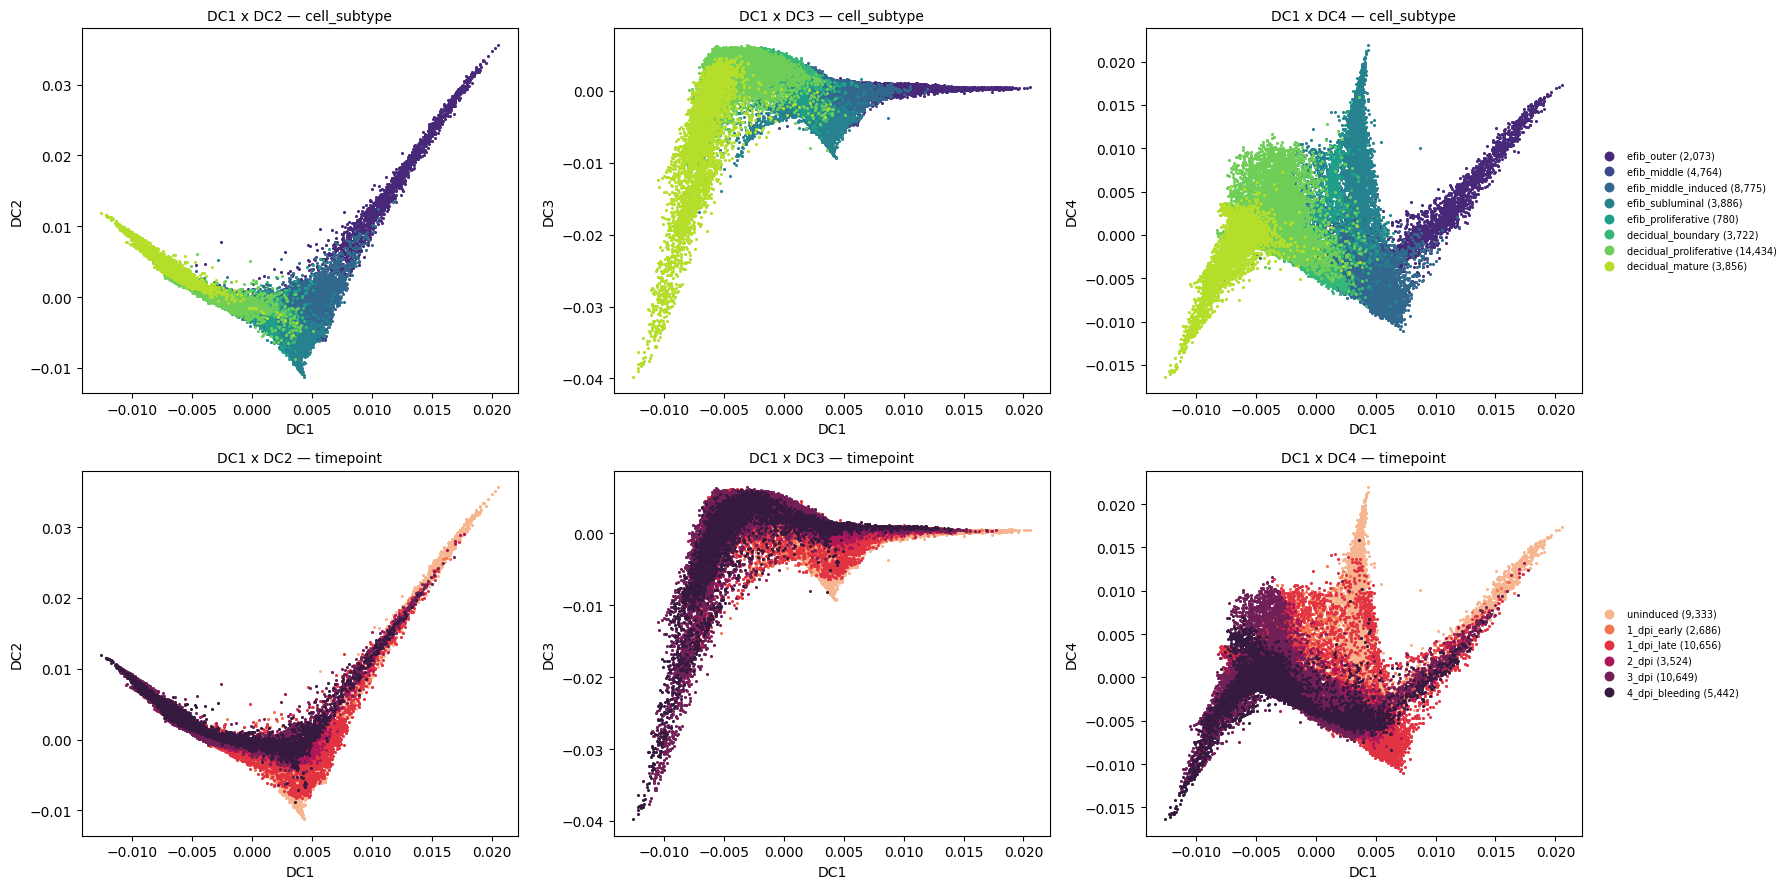

In [12]:
rank_sub = O.cell_subtype.map(RANK).to_numpy(float)
rows = []
for k in range(1, NDC+1):
    v = DM[:, k]; lo, hi = np.percentile(v, 2), np.percentile(v, 98)
    top = lambda m, col: ", ".join(f"{i} {100*x:.0f}%" for i, x in O.loc[m, col].value_counts(normalize=True).head(2).items())
    r = float(spearmanr(v, rank_sub).statistic)
    rows.append(dict(DC=f"DC{k}", rho_subtype_rank=round(r,3), early_end=("max" if r < 0 else "min"),
                     low_tail=top(v<=lo,"cell_subtype")+"  |  "+top(v<=lo,"timepoint"),
                     high_tail=top(v>=hi,"cell_subtype")+"  |  "+top(v>=hi,"timepoint")))
ORIENT = pd.DataFrame(rows).set_index("DC"); display(ORIENT)
BEST = ORIENT.rho_subtype_rank.abs().idxmax(); BEST_DC = int(BEST[2:]); EARLY = ORIENT.loc[BEST, "early_end"]
print(f"\nstrongest differentiation axis: {BEST} (rho {ORIENT.loc[BEST,'rho_subtype_rank']:+.3f}) -> early end is its {EARLY.upper()}")

def dc_panels(pairs=None, mark=None):
    pairs = pairs or [(BEST_DC, k) for k in range(1, min(NDC, 5)+1) if k != BEST_DC][:3]
    fig, axes = plt.subplots(2, len(pairs), figsize=(6*len(pairs), 9), squeeze=False)
    for j,(x,y) in enumerate(pairs):
        for i,(cmap_,col) in enumerate(((PAL,"cell_subtype"),(TPAL,"timepoint"))):
            ax = axes[i][j]
            for cat in [s for s in (SUBORDER if col=="cell_subtype" else TPORDER) if s in set(O[col])]:
                m = (O[col]==cat).to_numpy(); ax.scatter(DM[m,x], DM[m,y], s=1.5, c=[cmap_[cat]], label=f"{cat} ({m.sum():,})", rasterized=True)
            if mark:
                for bc, mk, cl in mark:
                    p = O.index.get_loc(bc); ax.scatter(DM[p,x], DM[p,y], s=180, marker=mk, c=cl, edgecolor="k", lw=.9, zorder=6)
            ax.set_xlabel(f"DC{x}"); ax.set_ylabel(f"DC{y}"); ax.set_title(f"DC{x} x DC{y} — {col}", fontsize=10)
            if j == len(pairs)-1: ax.legend(fontsize=7, markerscale=5, loc="center left", bbox_to_anchor=(1.02,.5), frameon=False)
    fig.tight_layout(); return fig
_ = dc_panels()

## 5 — **choose the root** (edit this cell)

`side="early"` resolves to whichever end §4 found for that DC, so you don't have to track the sign. `pct=0` = the single most extreme cell in the filtered pool; `pct=2` = the cell nearest the 2nd/98th percentile (more robust to a lone outlier). `root_grid()` lists every subtype × timepoint option. A literal `ROOT_BARCODE` overrides the spec.

Default: the most extreme **uninduced `efib_outer`** cell — the start of your stated order, in resting tissue.

all root options (depth 1.00 = deepest into the early pole):


,subtype,timepoint,pool,barcode,depth_into_early_pole,has_coords
0,efib_outer,uninduced,1007,CATGCTCCATATGCGT-1-uninduced_mck8b,1.0000,False
1,efib_outer,2_dpi,153,GTAGTACGTGAACTAA-1-2_dpi_mck15,0.9982,True
2,efib_outer,1_dpi_late,362,ACAAGCTAGATCCGAG-1-1_dpi_late_mck12a,0.9975,False
3,efib_outer,3_dpi,348,GAGGGATCAACAAAGT-1-3_dpi_mck10b,0.9968,False
4,efib_outer,1_dpi_early,70,CTTAGGATCCAACTAG-1-1_dpi_early_mck1,0.9957,False
5,efib_outer,4_dpi_bleeding,133,TGGCGTGAGCGGTAGT-1-4_dpi_bleeding_mck11a,0.9886,False
6,efib_middle_induced,1_dpi_late,3734,AATCGTGGTTCATCGA-1-1_dpi_late_mck12a,0.9797,True
7,efib_middle_induced,uninduced,611,GCCATGGAGTGGTGAC-1-uninduced_mck8a,0.9791,True
8,efib_middle_induced,4_dpi_bleeding,1086,CAGAGCCGTAGTAAGT-1-4_dpi_bleeding_mck11a,0.9729,True
9,efib_middle_induced,2_dpi,920,TGAGCATTCACTCCGT-1-2_dpi_mck15,0.9651,True



root: CATGCTCCATATGCGT-1-uninduced_mck8b
  {'dc': None, 'side': 'early', 'pct': 0, 'timepoint': 'uninduced', 'subtype': 'efib_outer'} -> DC1 max, pool 1007
  subtype=efib_outer  timepoint=uninduced  sample=uninduced_mck8b  section=nan
  depth into early pole of DC1: 1.0000
PASS  root is at the early end of the main axis (depth > 0.9)   [True]
PASS  root subtype is early in SUBORDER (index <= 2)   [True]  a late-subtype root pins that subtype to 0 and drags earlier ones behind it


True

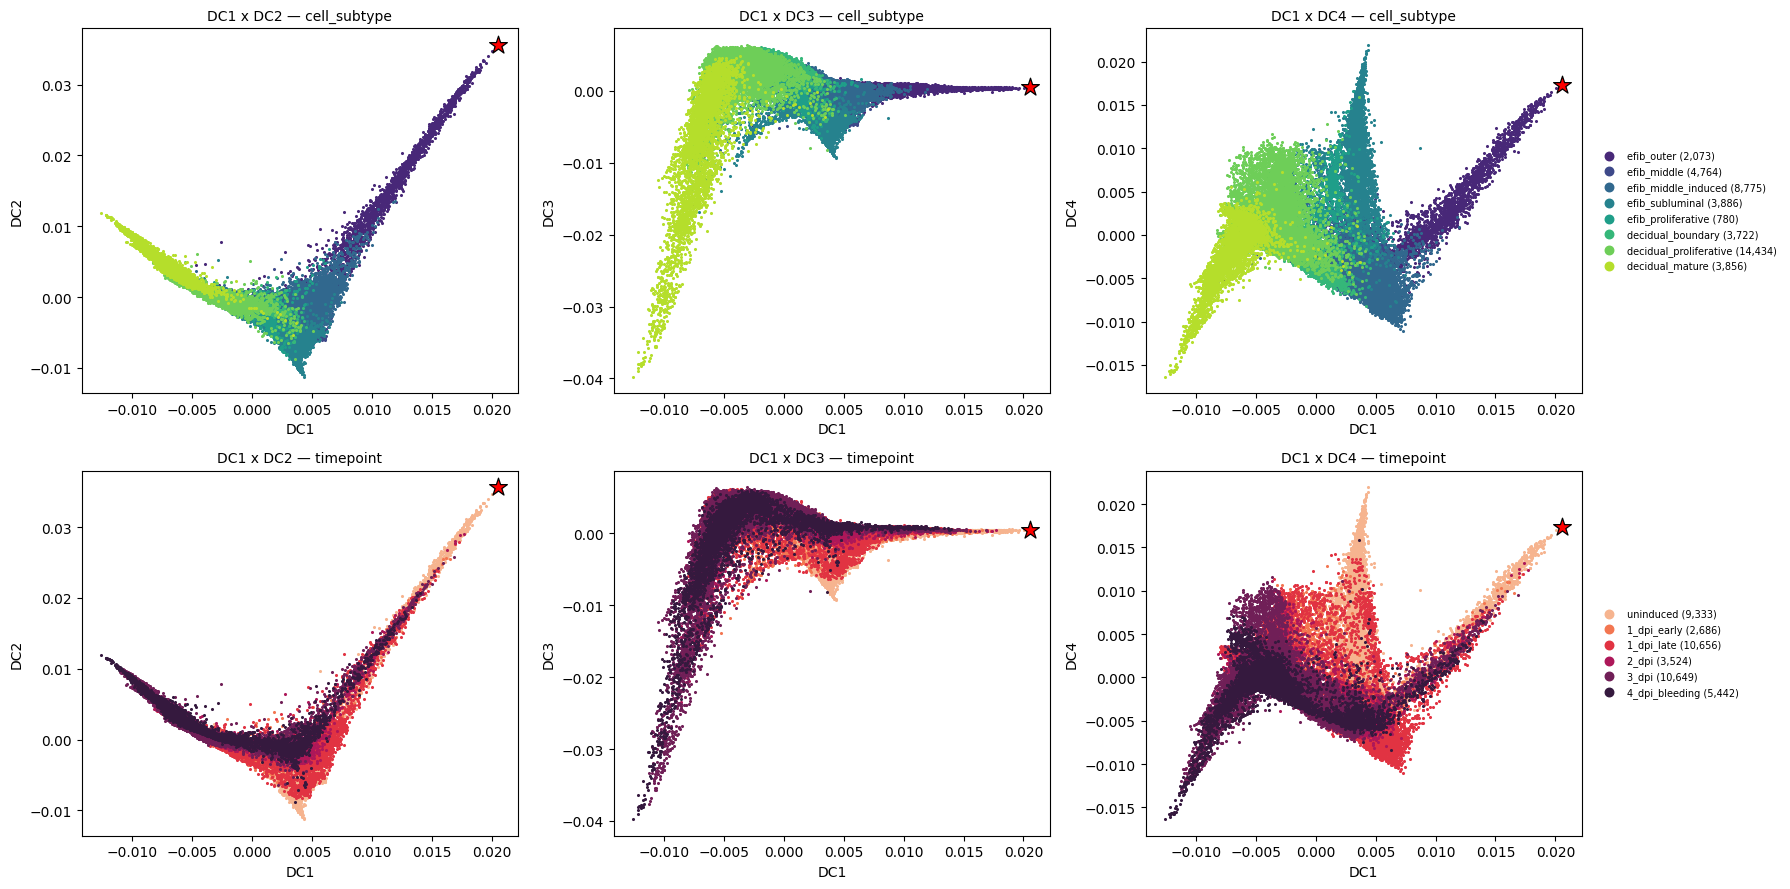

In [13]:
def _resolve(dc=None, side="early", pct=0, subtype=None, timepoint=None):
    dc = dc or BEST_DC
    side = (ORIENT.loc[f"DC{dc}", "early_end"] if side == "early" else side)
    m = np.ones(len(O), bool)
    if subtype   is not None: m &= (O.cell_subtype == subtype).to_numpy()
    if timepoint is not None: m &= (O.timepoint == timepoint).to_numpy()
    if not m.any(): return None
    v = DM[m, dc]
    if pct == 0: j = int(np.argmax(v)) if side == "max" else int(np.argmin(v))
    else:
        q = np.percentile(v, 100-pct if side == "max" else pct); j = int(np.argmin(np.abs(v - q)))
    idx = int(np.flatnonzero(m)[j]); return O.index[idx], idx, int(m.sum()), dc, side

def root_grid(dc=None, side="early", pct=0, min_pool=50):
    out = []
    for s in [x for x in SUBORDER if x in set(O.cell_subtype)]:
        for t in [x for x in TPORDER if x in set(O.timepoint)]:
            r = _resolve(dc, side, pct, s, t)
            if r and r[2] >= min_pool:
                bc, idx, n, d, sd = r
                out.append(dict(subtype=s, timepoint=t, pool=n, barcode=bc,
                    depth_into_early_pole=round(float((DM[:,d] < DM[idx,d]).mean() if sd=="max" else (DM[:,d] > DM[idx,d]).mean()),4),
                    has_coords=bool(np.isfinite(pd.to_numeric(O.x_um_qc.iloc[idx], errors="coerce")))))
    return pd.DataFrame(out).sort_values("depth_into_early_pole", ascending=False).reset_index(drop=True)
print("all root options (depth 1.00 = deepest into the early pole):"); display(root_grid().head(20))

# ------------------------------------------------------------------ EDIT HERE
ROOT = dict(dc=None, side="early", pct=0, timepoint="uninduced", subtype="efib_outer")
ROOT_BARCODE = None
# ------------------------------------------------------------------
if ROOT_BARCODE:
    assert ROOT_BARCODE in O.index; ROOT_BC, ROOT_IDX = ROOT_BARCODE, int(O.index.get_loc(ROOT_BARCODE)); ROOT_DESC = f"explicit barcode {ROOT_BARCODE}"
else:
    ROOT_BC, ROOT_IDX, npool, dc_used, side_used = _resolve(**ROOT); ROOT_DESC = f"{ROOT} -> DC{dc_used} {side_used}, pool {npool}"
depth = float((DM[:,BEST_DC] < DM[ROOT_IDX,BEST_DC]).mean() if EARLY=="max" else (DM[:,BEST_DC] > DM[ROOT_IDX,BEST_DC]).mean())
print(f"\nroot: {ROOT_BC}\n  {ROOT_DESC}\n  subtype={O.cell_subtype.iloc[ROOT_IDX]}  timepoint={O.timepoint.iloc[ROOT_IDX]}  "
      f"sample={O['sample'].iloc[ROOT_IDX]}  section={O.tissue_section.iloc[ROOT_IDX]}\n  depth into early pole of {BEST}: {depth:.4f}")
_ = dc_panels(mark=[(ROOT_BC, "*", "red")])
verify("root is at the early end of the main axis (depth > 0.9)", depth > 0.9)
verify("root subtype is early in SUBORDER (index <= 2)", RANK[O.cell_subtype.iloc[ROOT_IDX]] <= 2,
       note="a late-subtype root pins that subtype to 0 and drags earlier ones behind it")

## 6 — DPT and Palantir from that root

In [14]:
import palantir
res = pd.DataFrame(index=O.index); res.index.name = "cell"
for c in ("cell_subtype","timepoint","sample","tissue_section","spatial_qc_reason"): res[c] = O[c].to_numpy()
res["x_um"] = pd.to_numeric(O.x_um_qc, errors="coerce").to_numpy(float)
res["y_um"] = pd.to_numeric(O.y_um_qc, errors="coerce").to_numpy(float)

a.uns["iroot"] = ROOT_IDX
sc.tl.dpt(a, n_dcs=min(10, DM.shape[1]))
res["dpt"] = a.obs["dpt_pseudotime"].to_numpy(float)
verify("DPT is 0 at the root", float(res.dpt.iloc[ROOT_IDX]) == 0.0)
verify("DPT finite everywhere", bool(np.isfinite(res.dpt).all()), note=f"{int((~np.isfinite(res.dpt)).sum())} non-finite (disconnected cells)")

dmap = palantir.utils.run_diffusion_maps(pd.DataFrame(a.obsm["X_scVI"], index=O.index), n_components=10, knn=30)
ms   = palantir.utils.determine_multiscale_space(dmap)
pr   = palantir.core.run_palantir(ms, ROOT_BC, num_waypoints=1200, n_jobs=8, use_early_cell_as_start=True, seed=SEED)
res["palantir"] = pr.pseudotime.reindex(O.index).to_numpy(float)
verify("Palantir is 0 at the root (root honoured)", float(res.palantir.iloc[ROOT_IDX]) == 0.0,
       note="False = use_early_cell_as_start was ignored and Palantir re-picked its own start")
verify("Palantir minimum IS the root", res.palantir.idxmin() == ROOT_BC)
print("spearman(DPT, Palantir) =", round(float(spearmanr(res.dpt, res.palantir, nan_policy="omit").statistic), 4))

PASS  DPT is 0 at the root   [True]
PASS  DPT finite everywhere   [True]  0 non-finite (disconnected cells)
Sampling and flocking waypoints...
Time for determining waypoints: 0.0004084388415018717 minutes
Determining pseudotime...
Shortest path distances using 30-nearest neighbor graph...
Time for shortest paths: 0.9660616676012675 minutes
Iteratively refining the pseudotime...
Correlation at iteration 1: 0.9961
Correlation at iteration 2: 0.9999
Correlation at iteration 3: 1.0000
Entropy and branch probabilities...
Markov chain construction...
Identification of terminal states...
Computing fundamental matrix and absorption probabilities...
Project results to all cells...
PASS  Palantir is 0 at the root (root honoured)   [True]  False = use_early_cell_as_start was ignored and Palantir re-picked its own start
PASS  Palantir minimum IS the root   [True]
spearman(DPT, Palantir) = 0.93


## 7 — quantile normalisation

`*_q` = each cell's percentile among all cells: same ordering as the raw pseudotime (asserted), uniform spacing, so the compressed decidual tail becomes readable without deleting cells. `*_qsec` normalises within tissue section — for comparing trajectory *shape* across sections only; it cannot say one section is further along.

PASS  quantile transform preserves ordering exactly   [True]


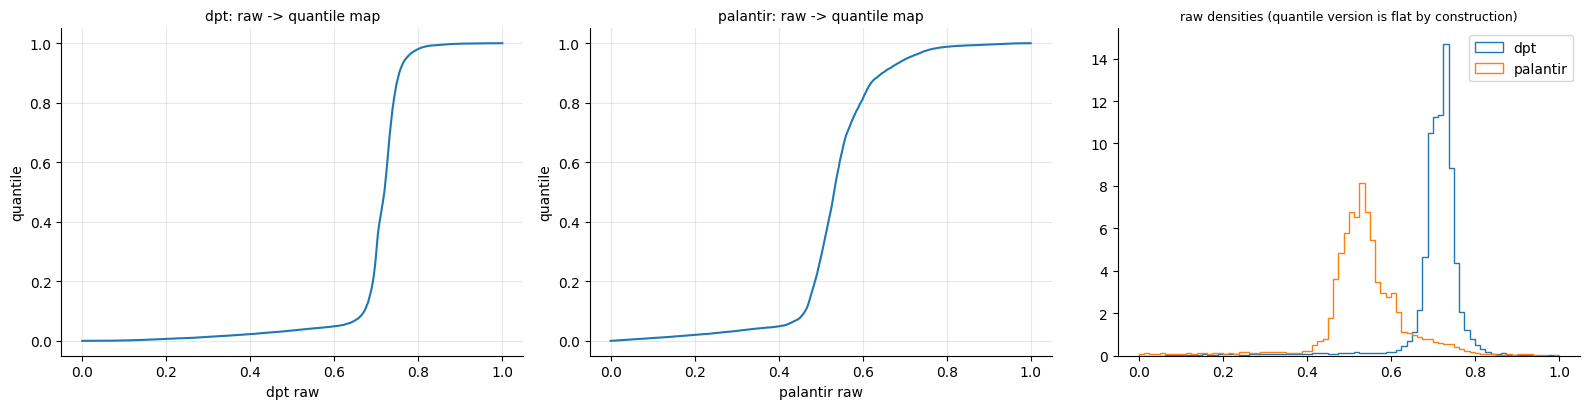

In [15]:
for m in ("dpt","palantir"):
    res[f"{m}_q"]    = res[m].rank(pct=True)
    res[f"{m}_qsec"] = res.groupby("tissue_section", observed=True)[m].rank(pct=True)
verify("quantile transform preserves ordering exactly", float(spearmanr(res.palantir, res.palantir_q, nan_policy="omit").statistic) == 1.0)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, m in zip(axes[:2], ("dpt","palantir")):
    v = np.sort(res[m].dropna()); ax.plot(v, np.linspace(0,1,len(v)), lw=1.5); ax.grid(alpha=.3)
    ax.set_xlabel(f"{m} raw"); ax.set_ylabel("quantile"); ax.set_title(f"{m}: raw -> quantile map", fontsize=10)
for m, c in (("dpt","C0"),("palantir","C1")): axes[2].hist(res[m].dropna(), bins=80, histtype="step", density=True, color=c, label=m)
axes[2].legend(); axes[2].set_title("raw densities (quantile version is flat by construction)", fontsize=9); fig.tight_layout()

## 8 — orientation gates (REFUSED, never flipped)

Pooled correlations are dominated by the decidual arm, so the fibroblast-only and uninduced-only columns are the ones that catch a backwards fibroblast ordering. `pinned` lists subtypes earlier than the root's own subtype whose median pseudotime nonetheless lands *after* it.

In [16]:
def gates(pt):
    sr = O.cell_subtype.map(RANK).to_numpy(float); tr = O.timepoint.map(TPRANK).to_numpy(float); ok = np.isfinite(pt)
    fib = ok & O.cell_subtype.str.startswith("efib").to_numpy(); dec = ok & ~O.cell_subtype.str.startswith("efib").to_numpy()
    un  = ok & (O.timepoint=="uninduced").to_numpy()
    rho = lambda m, y: round(float(spearmanr(pt[m], y[m]).statistic), 4) if m.sum() > 50 else None
    root_sub = O.cell_subtype.iloc[ROOT_IDX]
    med = pd.Series(pt, index=O.index).groupby(O.cell_subtype).median()
    pinned = [s for s in SUBORDER[:RANK[root_sub]] if s in med.index and med[s] > med[root_sub]]
    d = dict(rho_subtype_all=rho(ok, sr), rho_subtype_fibroblasts=rho(fib, sr), rho_subtype_uninduced=rho(un, sr),
             rho_day_all=rho(ok, tr), rho_day_decidual_only=rho(dec, tr), rho_day_fibroblasts_only=rho(fib, tr),
             root_subtype=root_sub, pinned_behind_root=pinned)
    bad = any(v is not None and v <= 0 for v in (d["rho_subtype_all"], d["rho_subtype_fibroblasts"], d["rho_day_decidual_only"]))
    d["verdict"] = "REFUSED — orientation gate failed; NOT flipped, choose another root" if bad else ("OK (root-pinned: %s)" % ", ".join(pinned) if pinned else "OK")
    return d
GATES = {m: gates(res[m].to_numpy()) for m in ("dpt","palantir")}; display(pd.DataFrame(GATES).T)
for m, g in GATES.items():
    verify(f"{m}: orientation", g["verdict"].startswith("OK"), note=g["verdict"])
    verify(f"{m}: fibroblast arm ordered forwards", (g["rho_subtype_fibroblasts"] or 0) > 0)
    verify(f"{m}: no subtype pinned behind the root", not g["pinned_behind_root"], note=str(g["pinned_behind_root"]))

,rho_subtype_all,rho_subtype_fibroblasts,rho_subtype_uninduced,rho_day_all,rho_day_decidual_only,rho_day_fibroblasts_only,root_subtype,pinned_behind_root,verdict
dpt,0.849,0.5196,0.7455,0.4106,0.2977,-0.3128,efib_outer,[],OK
palantir,0.7445,0.4957,0.6837,0.3107,0.3049,-0.3181,efib_outer,[],OK


PASS  dpt: orientation   [True]  OK
PASS  dpt: fibroblast arm ordered forwards   [True]
PASS  dpt: no subtype pinned behind the root   [True]  []
PASS  palantir: orientation   [True]  OK
PASS  palantir: fibroblast arm ordered forwards   [True]
PASS  palantir: no subtype pinned behind the root   [True]  []


## 9 — violins, raw vs quantile, by subtype and by timepoint

median Palantir quantile by timepoint x compartment (pooled violins are composition-driven):


compartment,decidual,fibroblast
timepoint,,
uninduced,0.301,0.342
1_dpi_early,0.498,0.188
1_dpi_late,0.603,0.173
2_dpi,0.679,0.130
3_dpi,0.743,0.204
4_dpi_bleeding,0.723,0.202



median by subtype, within uninduced only (the ordering check by eye):


,dpt_q,palantir_q
cell_subtype,,
efib_outer,0.014,0.013
efib_middle,0.287,0.307
efib_middle_induced,0.212,0.227
efib_subluminal,0.496,0.787
efib_proliferative,0.443,0.399
decidual_boundary,0.328,0.297
decidual_proliferative,0.316,0.297
decidual_mature,0.389,0.720


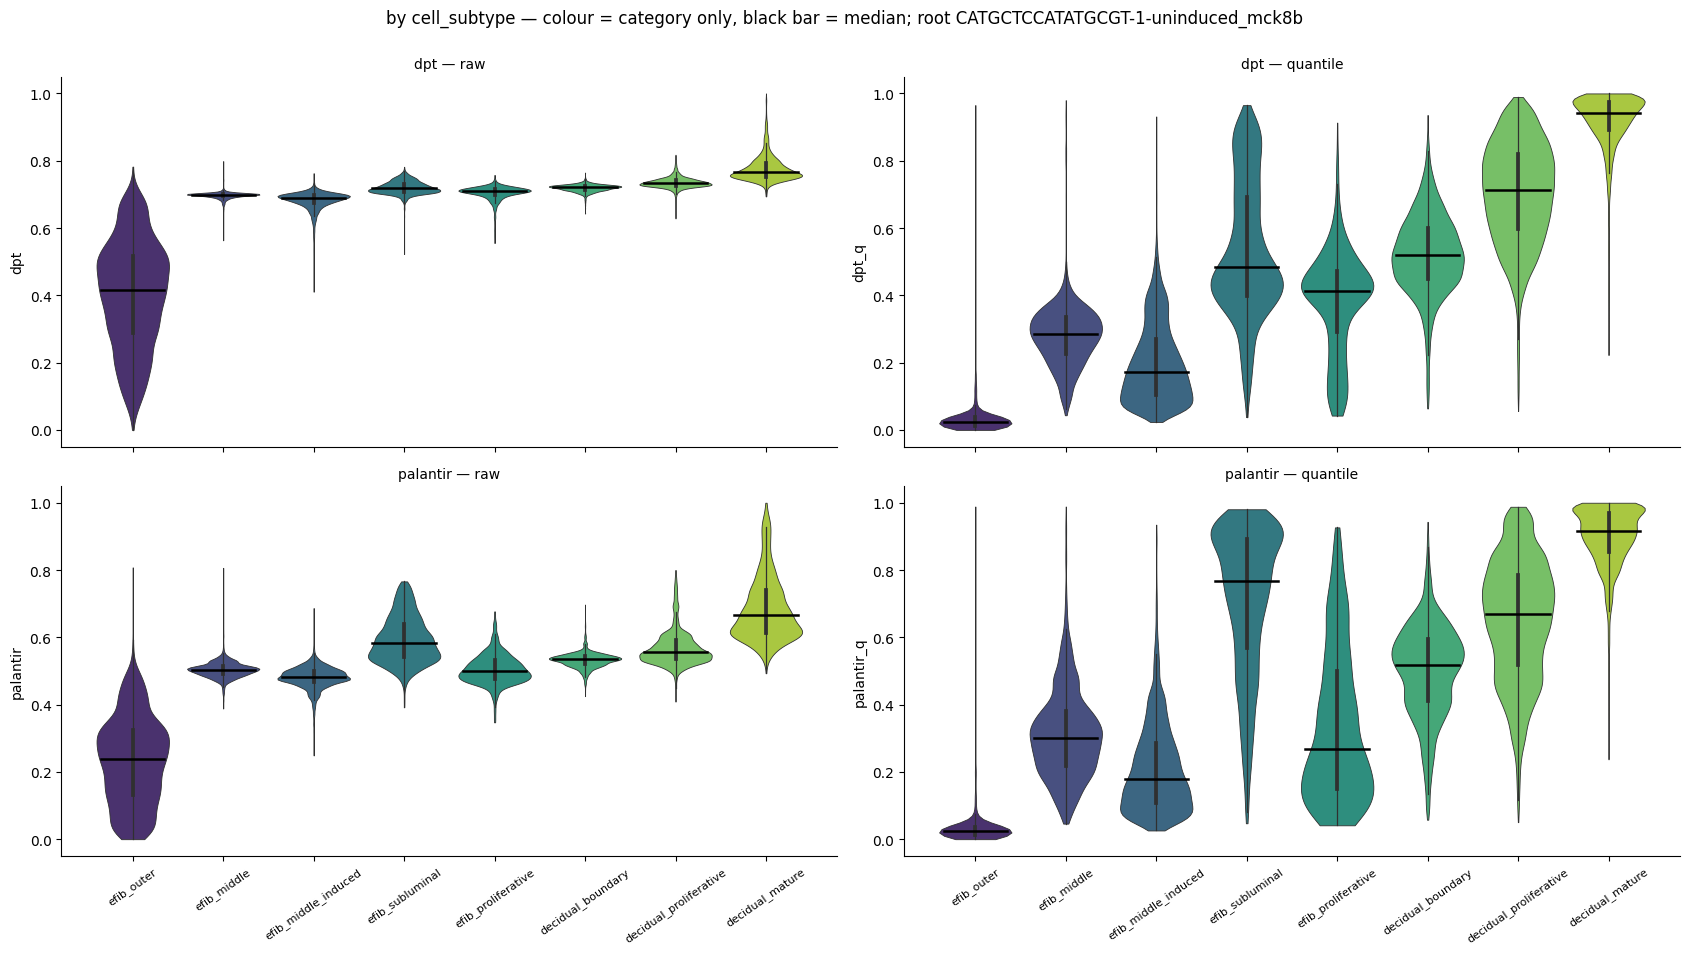

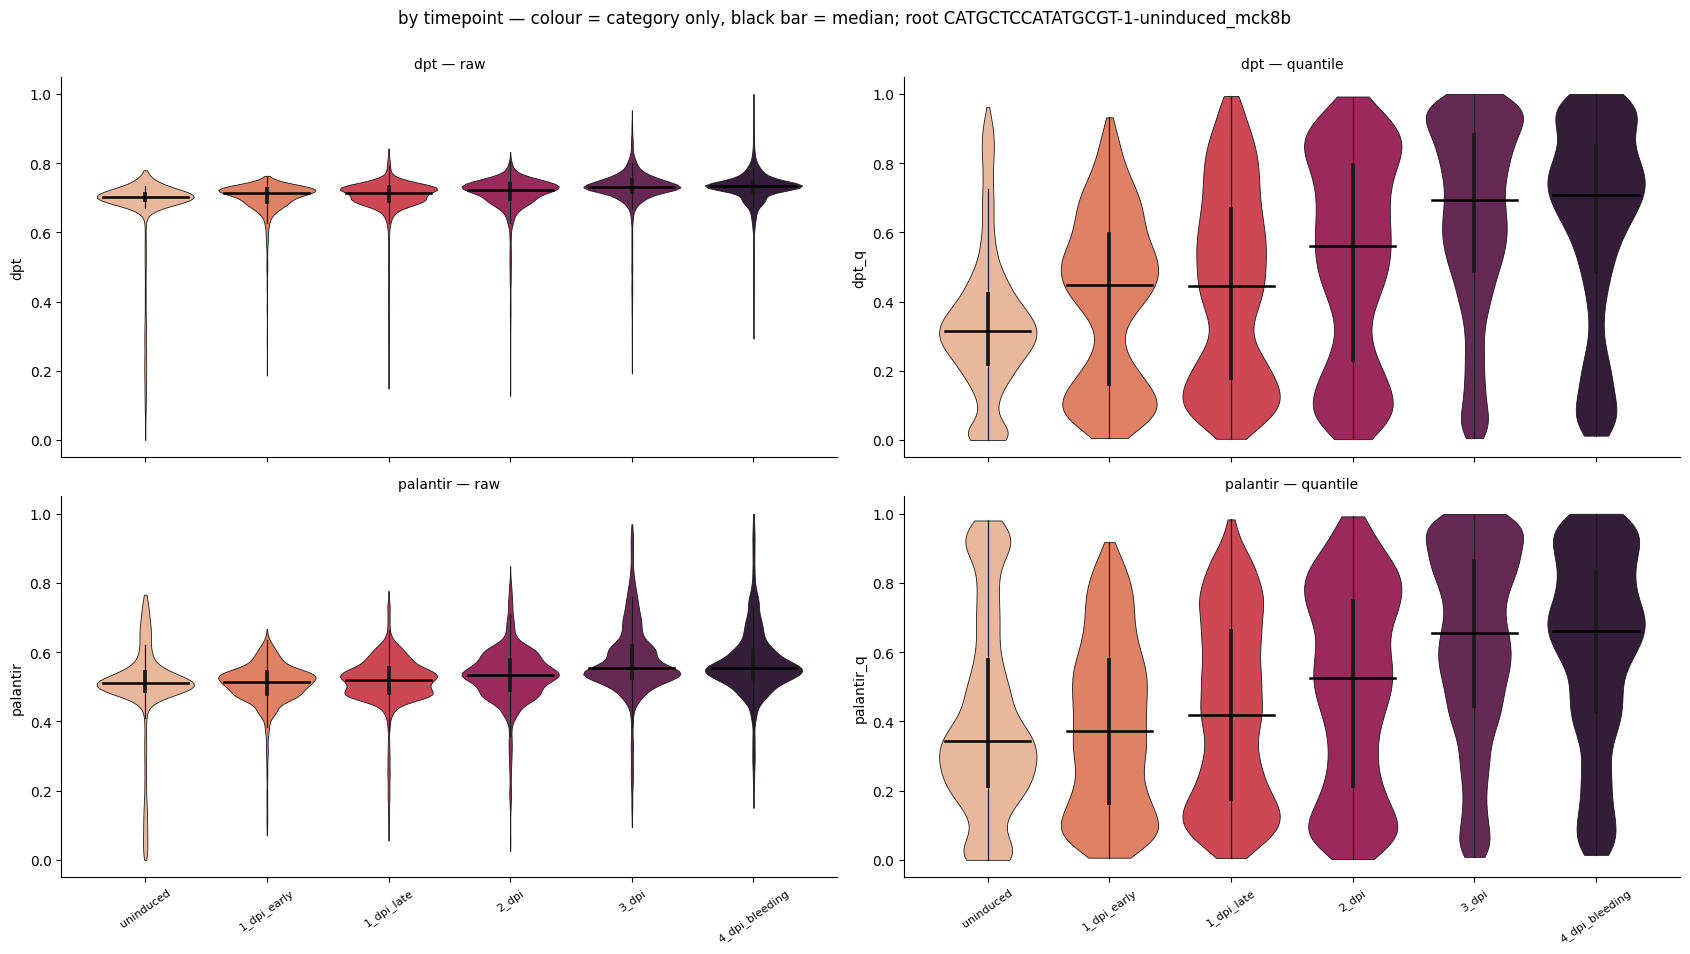

In [17]:
def violins(by):
    order = [s for s in (SUBORDER if by=="cell_subtype" else TPORDER) if s in set(res[by])]; pal = PAL if by=="cell_subtype" else TPAL
    fig, axes = plt.subplots(2, 2, figsize=(17, 9.5), sharex=True)
    for i, m in enumerate(("dpt","palantir")):
        for j, col in enumerate((m, f"{m}_q")):
            ax = axes[i][j]
            sns.violinplot(data=res, x=by, y=col, order=order, hue=by, hue_order=order, palette=pal, legend=False, cut=0, linewidth=.6, ax=ax)
            med = res.groupby(by, observed=True)[col].median()
            for k, cat in enumerate(order): ax.plot([k-.35,k+.35],[med[cat]]*2, c="k", lw=1.8, zorder=5)
            ax.set_title(f"{m} — {'quantile' if col.endswith('_q') else 'raw'}", fontsize=10); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=35, labelsize=8)
    fig.suptitle(f"by {by} — colour = category only, black bar = median; root {ROOT_BC}", y=1.0); fig.tight_layout(); return fig
_ = violins("cell_subtype"); _ = violins("timepoint")
res["compartment"] = np.where(res.cell_subtype.str.startswith("efib"), "fibroblast", "decidual")
print("median Palantir quantile by timepoint x compartment (pooled violins are composition-driven):")
display(res.pivot_table(index="timepoint", columns="compartment", values="palantir_q", aggfunc="median", observed=True).reindex(TPORDER).round(3))
print("\nmedian by subtype, within uninduced only (the ordering check by eye):")
display(res[res.timepoint=="uninduced"].groupby("cell_subtype")[["dpt_q","palantir_q"]].median().reindex([s for s in SUBORDER if s in set(res.cell_subtype)]).round(3))

## 10 — spatial: raw, quantile (global), quantile (within section)

One row per tissue section, ordered by timepoint. Sections are never pooled within a timepoint (`mck8a`/`mck8b` share a coordinate frame). Raw and global-quantile columns share one colour scale across all sections.

23,123 of 42,290 cells have a QC'd coordinate | 11 sections | per timepoint: {t: len(v) for t, v in SEC_BY_TP.items()}


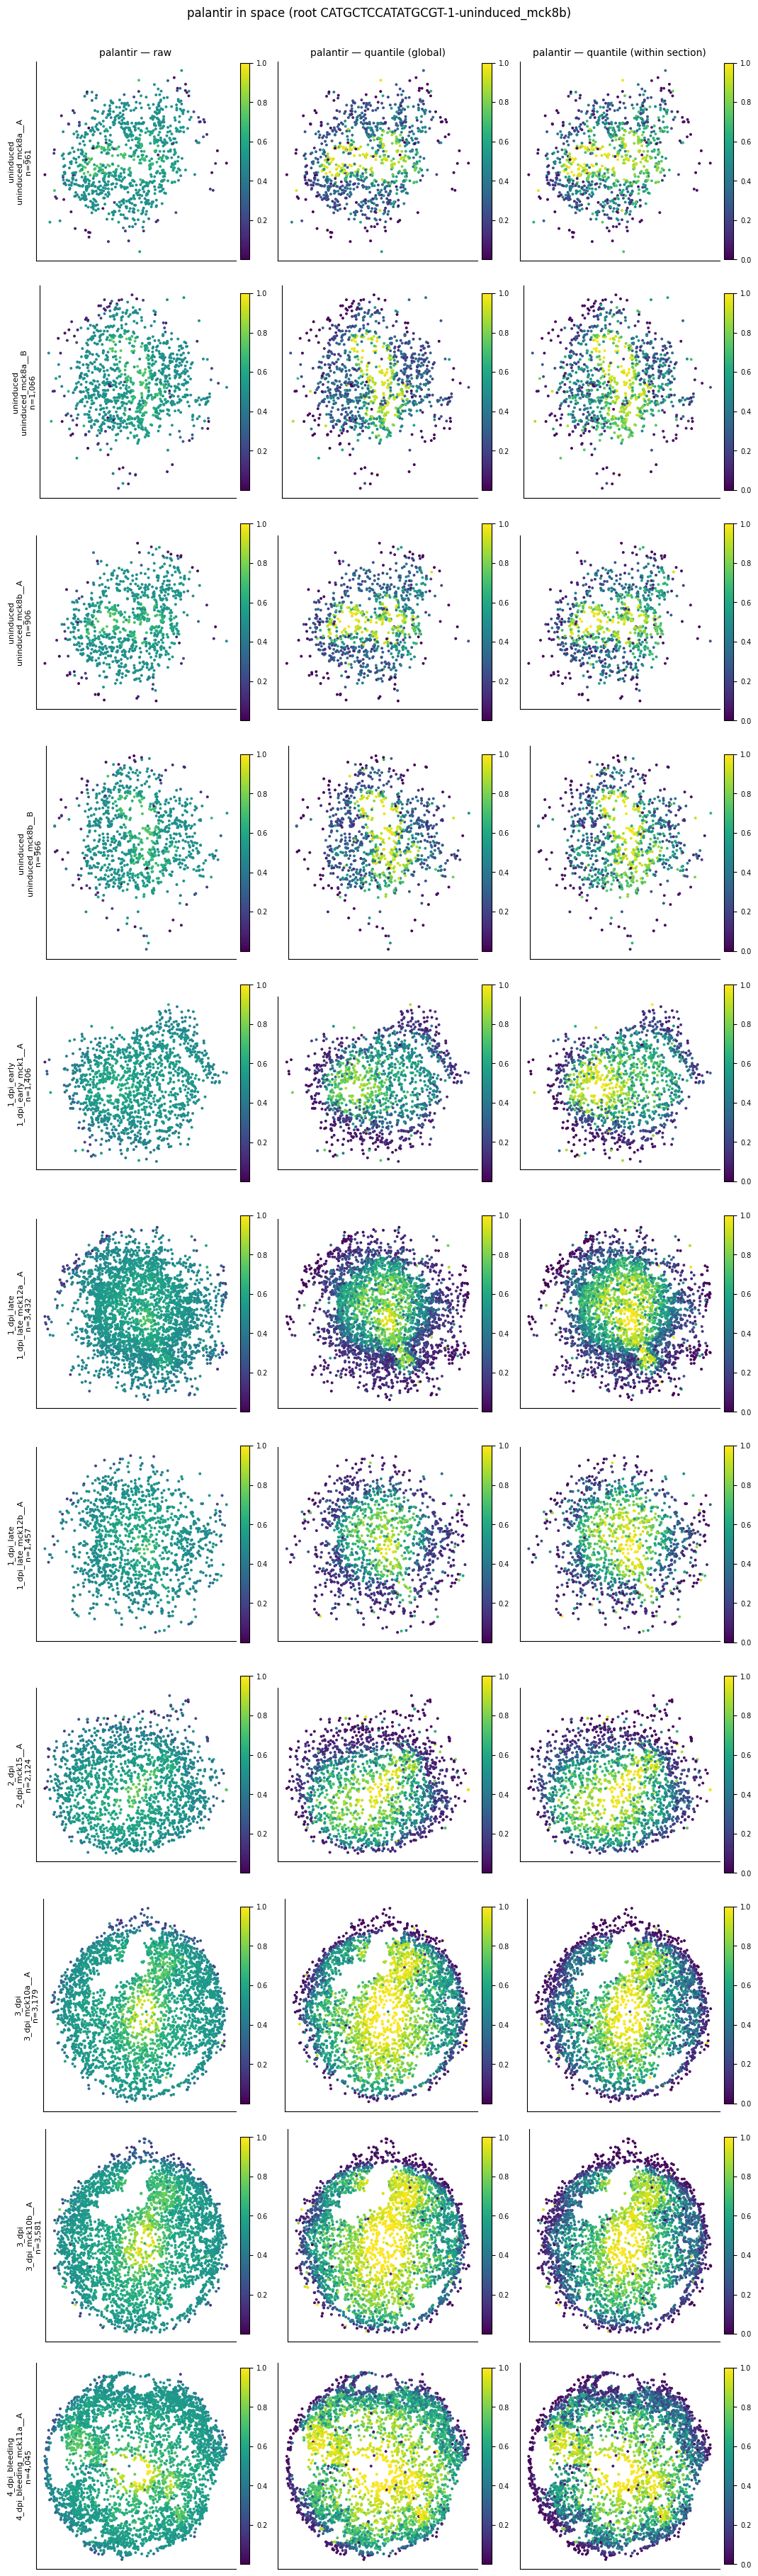

In [18]:
SP = res[np.isfinite(res.x_um) & res.tissue_section.notna()].copy()
SEC2TP = SP.groupby("tissue_section", observed=True).timepoint.first().to_dict()
secs = sorted(SP.tissue_section.unique(), key=lambda s: (TPRANK.get(SEC2TP[s], 99), s))
SEC_BY_TP = {t: [s for s in secs if SEC2TP[s]==t] for t in TPORDER if any(SEC2TP[s]==t for s in secs)}
print(f"{len(SP):,} of {len(res):,} cells have a QC'd coordinate | {len(secs)} sections | per timepoint: {{t: len(v) for t, v in SEC_BY_TP.items()}}")

def spatial_panels(method="palantir", cols=("","_q","_qsec"), per=3.6, s=3.4):
    labs = {"":"raw","_q":"quantile (global)","_qsec":"quantile (within section)"}
    fig, axes = plt.subplots(len(secs), len(cols), figsize=(per*len(cols), per*len(secs)*.92), squeeze=False)
    for i, sec in enumerate(secs):
        g = SP[SP.tissue_section==sec]
        for j, suf in enumerate(cols):
            ax = axes[i][j]; col = f"{method}{suf}"; vmin, vmax = ((SP[col].min(), SP[col].max()) if suf!="_qsec" else (0,1))
            sm = ax.scatter(g.x_um, g.y_um, c=g[col], s=s, cmap="viridis", vmin=vmin, vmax=vmax, rasterized=True)
            ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
            if i==0: ax.set_title(f"{method} — {labs[suf]}", fontsize=10)
            if j==0: ax.set_ylabel(f"{SEC2TP[sec]}\n{sec}\nn={len(g):,}", fontsize=8)
            plt.colorbar(sm, ax=ax, fraction=.046, pad=.02).ax.tick_params(labelsize=7)
    fig.suptitle(f"{method} in space (root {ROOT_BC})", y=1.0); fig.tight_layout(); return fig

def spatial_by_timepoint(method="palantir", suffix="_q", per=3.5, s=3.4):
    labs = {"":"raw","_q":"quantile (global)","_qsec":"quantile (within section)"}; col = f"{method}{suffix}"
    ncol = max(len(v) for v in SEC_BY_TP.values()); vmin, vmax = ((SP[col].min(), SP[col].max()) if suffix!="_qsec" else (0,1))
    fig, axes = plt.subplots(len(SEC_BY_TP), ncol, figsize=(per*ncol, per*len(SEC_BY_TP)*.95), squeeze=False)
    for i, (tp, sl) in enumerate(SEC_BY_TP.items()):
        for j in range(ncol):
            ax = axes[i][j]
            if j >= len(sl): ax.axis("off"); continue
            g = SP[SP.tissue_section==sl[j]]
            sm = ax.scatter(g.x_um, g.y_um, c=g[col], s=s, cmap="viridis", vmin=vmin, vmax=vmax, rasterized=True)
            ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"{sl[j].replace(tp+'_','')}  n={len(g):,}", fontsize=8)
            if j==0: ax.set_ylabel(tp, fontsize=10)
            plt.colorbar(sm, ax=ax, fraction=.046, pad=.02).ax.tick_params(labelsize=7)
    fig.suptitle(f"{method} — {labs[suffix]}, by timepoint (root {ROOT_BC})", y=1.0); fig.tight_layout(); return fig

_ = spatial_panels("palantir")

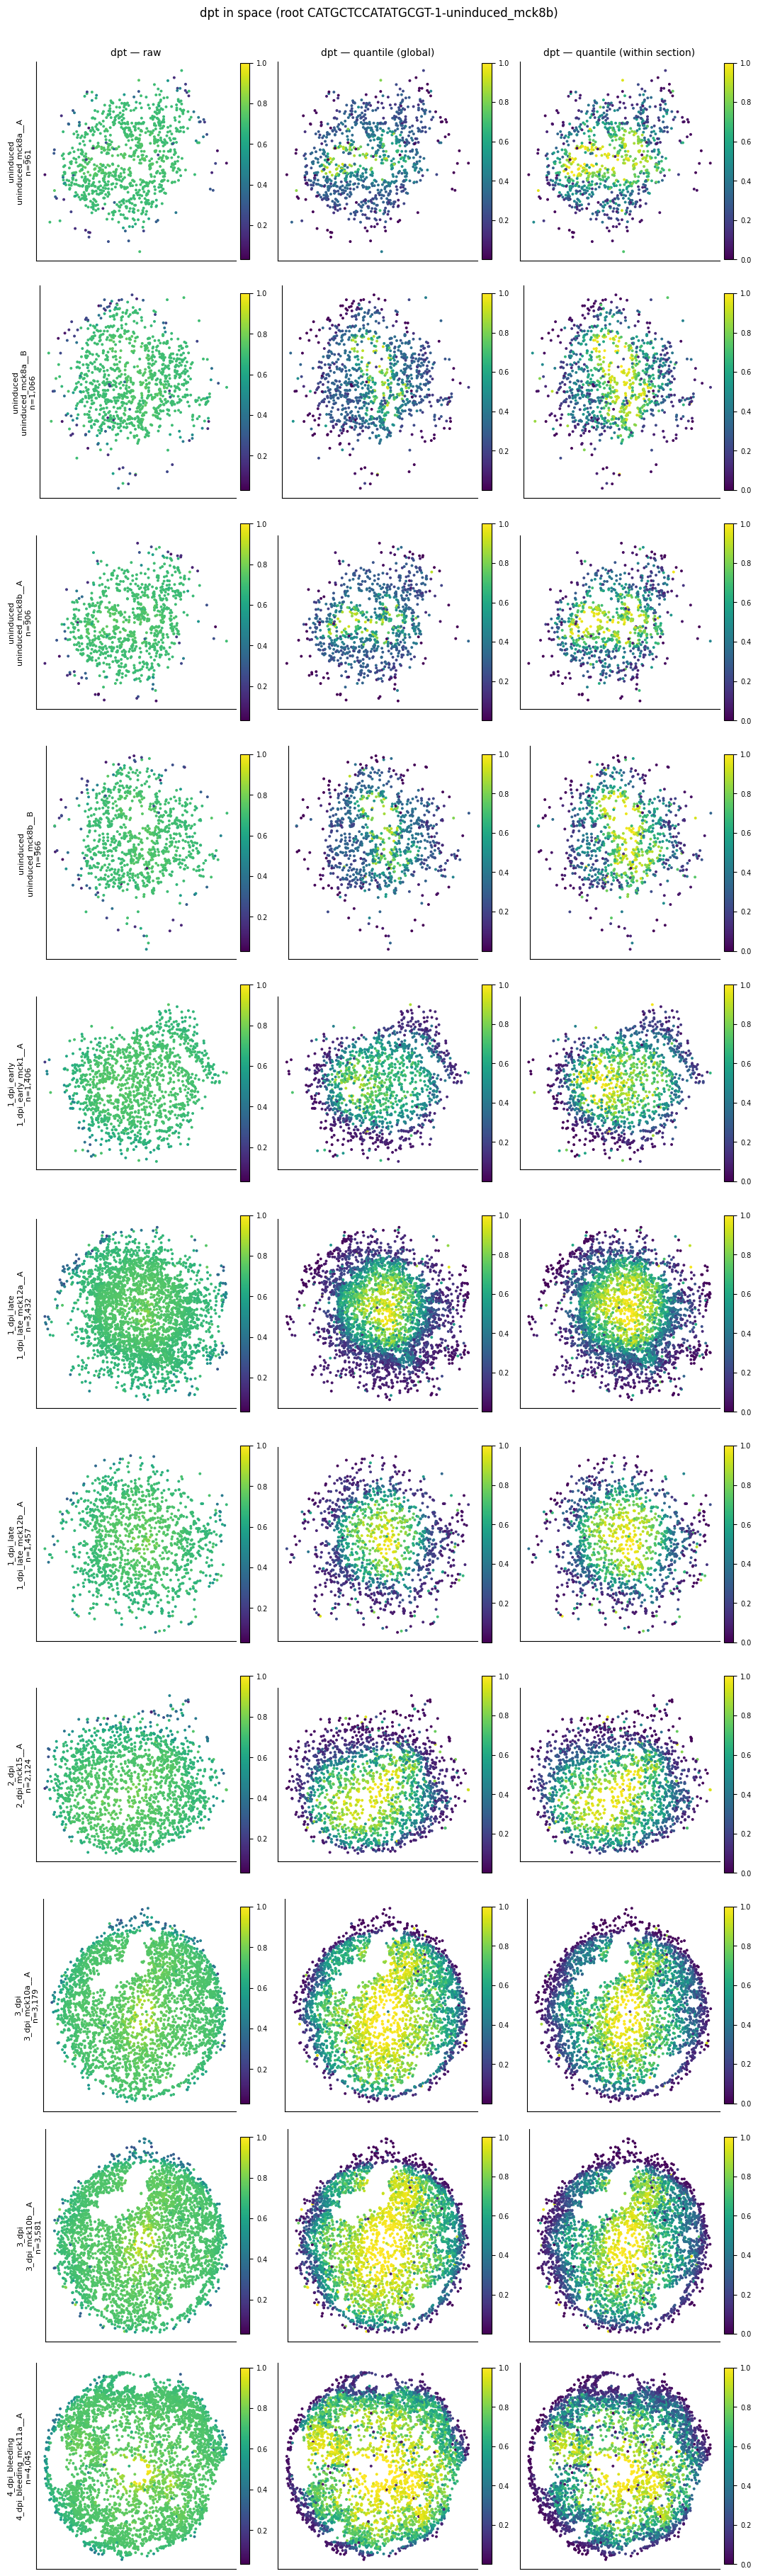

In [19]:
_ = spatial_panels("dpt")

In [ ]:
_ = spatial_by_timepoint("palantir", "_q"); _ = spatial_by_timepoint("palantir", "")

### Pseudotime vs isodepth per section (Spearman; unchanged by the quantile transform)

In [ ]:
if ISO.exists():
    with h5py.File(ISO, "r") as f:
        ic = [c for c in f["obs"].keys() if "isodepth" in c]; ICOL = "isodepth_consensus" if "isodepth_consensus" in ic else ic[0]
        iso = pd.Series(pd.to_numeric(read_elem(f[f"obs/{ICOL}"]), errors="coerce"), index=pd.Index(read_elem(f["obs/_index"])))
    SP["isodepth"] = iso.reindex(SP.index).to_numpy(float); m = np.isfinite(SP.isodepth)
    rows = [dict(section=sec, n=len(g), rho_palantir=round(float(spearmanr(g.palantir, g.isodepth).statistic),3),
                 rho_dpt=round(float(spearmanr(g.dpt, g.isodepth).statistic),3))
            for sec, g in SP[m].groupby("tissue_section", observed=True) if len(g) >= 100]
    display(pd.DataFrame(rows).set_index("section"))
else: print("isodepth object not found:", ISO)

## 11 — save

In [ ]:
tag = (ROOT_BARCODE or "_".join(str(ROOT.get(k)) for k in ("timepoint","subtype") if ROOT.get(k)) + f"_pct{ROOT['pct']}")
res["root_barcode"] = ROOT_BC; res["root_desc"] = ROOT_DESC
res.to_csv(OUT/f"pseudotime_{tag}.csv")
json.dump(dict(source=str(SRC), n_cells=int(len(res)), variant=VARIANT, dropped=a.uns["scvi"]["dropped"], kept=(["uninduced","efib_outer"] if "uninduced" in set(a.obs.timepoint) else ["efib_outer"]),
               scvi=a.uns["scvi"], root_barcode=ROOT_BC, root_desc=ROOT_DESC, spec=(ROOT_BARCODE or ROOT),
               main_axis=BEST, early_end=EARLY, gates=GATES, palantir_version=palantir.__version__,
               use_early_cell_as_start=True, checks=[dict(label=l, ok=o, got=g) for l,o,g,_ in CHECKS]),
          open(OUT/f"pseudotime_{tag}_report.json","w"), indent=1, default=str)
bad = [l for l,o,_,_ in CHECKS if not o]
print("wrote", OUT/f"pseudotime_{tag}.csv"); print(f"{len(CHECKS)} checks | {len(bad)} FAILED" + (": "+"; ".join(bad) if bad else " — all passed"))